<a href="https://colab.research.google.com/github/mrdbourke/pytorch-deep-learning/blob/main/extras/exercises/07_pytorch_experiment_tracking_exercise_template.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 07. PyTorch Experiment Tracking Exercise Template

Welcome to the 07. PyTorch Experiment Tracking exercise template notebook.

> **Note:** There may be more than one solution to each of the exercises. This notebook only shows one possible example.

## Resources

1. These exercises/solutions are based on [section 07. PyTorch Transfer Learning](https://www.learnpytorch.io/07_pytorch_experiment_tracking/) of the Learn PyTorch for Deep Learning course by Zero to Mastery.
2. See a live [walkthrough of the solutions (errors and all) on YouTube](https://youtu.be/cO_r2FYcAjU).
3. See [other solutions on the course GitHub](https://github.com/mrdbourke/pytorch-deep-learning/tree/main/extras/solutions).

> **Note:** The first section of this notebook is dedicated to getting various helper functions and datasets used for the exercises. The exercises start at the heading "Exercise 1: ...".

### Get various imports and helper functions

We'll need to make sure we have `torch` v.1.12+ and `torchvision` v0.13+.

In [1]:
import torch
import torchvision
import torch
import torchvision

In [2]:
# Make sure we have a GPU
device = "cuda" if torch.cuda.is_available() else "cpu"
device

'cuda'

In [3]:
# Get regular imports 
import matplotlib.pyplot as plt
import torch
import torchvision

from torch import nn
from torchvision import transforms

from torchinfo import summary

from going_modular import data_setup, engine

In [4]:
# Set seeds
def set_seeds(seed: int=42):
    """Sets random sets for torch operations.

    Args:
        seed (int, optional): Random seed to set. Defaults to 42.
    """
    # Set the seed for general torch operations
    torch.manual_seed(seed)
    # Set the seed for CUDA torch operations (ones that happen on the GPU)
    torch.cuda.manual_seed(seed)

In [5]:
import os
import zipfile

from pathlib import Path

import requests

def download_data(source: str, 
                  destination: str,
                  remove_source: bool = True) -> Path:
    """Downloads a zipped dataset from source and unzips to destination.

    Args:
        source (str): A link to a zipped file containing data.
        destination (str): A target directory to unzip data to.
        remove_source (bool): Whether to remove the source after downloading and extracting.
    
    Returns:
        pathlib.Path to downloaded data.
    
    Example usage:
        download_data(source="https://github.com/mrdbourke/pytorch-deep-learning/raw/main/data/pizza_steak_sushi.zip",
                      destination="pizza_steak_sushi")
    """
    # Setup path to data folder
    data_path = Path("data/")
    image_path = data_path / destination

    # If the image folder doesn't exist, download it and prepare it... 
    if image_path.is_dir():
        print(f"[INFO] {image_path} directory exists, skipping download.")
    else:
        print(f"[INFO] Did not find {image_path} directory, creating one...")
        image_path.mkdir(parents=True, exist_ok=True)
        
        # Download pizza, steak, sushi data
        target_file = Path(source).name
        with open(data_path / target_file, "wb") as f:
            request = requests.get(source)
            print(f"[INFO] Downloading {target_file} from {source}...")
            f.write(request.content)

        # Unzip pizza, steak, sushi data
        with zipfile.ZipFile(data_path / target_file, "r") as zip_ref:
            print(f"[INFO] Unzipping {target_file} data...") 
            zip_ref.extractall(image_path)

        # Remove .zip file
        if remove_source:
            os.remove(data_path / target_file)
    
    return image_path

image_path = download_data(source="https://github.com/mrdbourke/pytorch-deep-learning/raw/main/data/pizza_steak_sushi.zip",
                           destination="pizza_steak_sushi")
image_path

[INFO] data\pizza_steak_sushi directory exists, skipping download.


WindowsPath('data/pizza_steak_sushi')

In [6]:
from torch.utils.tensorboard import SummaryWriter
def create_writer(experiment_name: str, 
                  model_name: str, 
                  extra: str | None=None):
    """Creates a torch.utils.tensorboard.writer.SummaryWriter() instance saving to a specific log_dir.

    log_dir is a combination of runs/timestamp/experiment_name/model_name/extra.

    Where timestamp is the current date in YYYY-MM-DD format.

    Args:
        experiment_name (str): Name of experiment.
        model_name (str): Name of model.
        extra (str, optional): Anything extra to add to the directory. Defaults to None.

    Returns:
        torch.utils.tensorboard.writer.SummaryWriter(): Instance of a writer saving to log_dir.

    Example usage:
        # Create a writer saving to "runs/2022-06-04/data_10_percent/effnetb2/5_epochs/"
        writer = create_writer(experiment_name="data_10_percent",
                               model_name="effnetb2",
                               extra="5_epochs")
        # The above is the same as:
        writer = SummaryWriter(log_dir="runs/2022-06-04/data_10_percent/effnetb2/5_epochs/")
    """
    from datetime import datetime
    import os

    # Get timestamp of current date (all experiments on certain day live in same folder)
    timestamp = datetime.now().strftime("%Y-%m-%d") # returns current date in YYYY-MM-DD format

    if extra:
        # Create log directory path
        log_dir = os.path.join("runs", timestamp, experiment_name, model_name, extra)
    else:
        log_dir = os.path.join("runs", timestamp, experiment_name, model_name)
        
    print(f"[INFO] Created SummaryWriter, saving to: {log_dir}...")
    return SummaryWriter(log_dir=log_dir)

In [7]:
# Create a test writer
writer = create_writer(experiment_name="test_experiment_name",
                       model_name="this_is_the_model_name",
                       extra="add_a_little_extra_if_you_want")

[INFO] Created SummaryWriter, saving to: runs\2026-07-10\test_experiment_name\this_is_the_model_name\add_a_little_extra_if_you_want...


In [8]:
from typing import Dict, List
from tqdm.auto import tqdm
from torch.utils import tensorboard

from going_modular.engine import train_step, test_step

# Add writer parameter to train()
def train(model: torch.nn.Module, 
          train_dataloader: torch.utils.data.DataLoader, 
          test_dataloader: torch.utils.data.DataLoader, 
          optimizer: torch.optim.Optimizer,
          loss_fn: torch.nn.Module,
          epochs: int,
          device: torch.device | str, 
          writer: tensorboard.SummaryWriter | None=None # new parameter to take in a writer
          ) -> Dict[str, List]:
    """Trains and tests a PyTorch model.

    Passes a target PyTorch models through train_step() and test_step()
    functions for a number of epochs, training and testing the model
    in the same epoch loop.

    Calculates, prints and stores evaluation metrics throughout.

    Stores metrics to specified writer log_dir if present.

    Args:
      model: A PyTorch model to be trained and tested.
      train_dataloader: A DataLoader instance for the model to be trained on.
      test_dataloader: A DataLoader instance for the model to be tested on.
      optimizer: A PyTorch optimizer to help minimize the loss function.
      loss_fn: A PyTorch loss function to calculate loss on both datasets.
      epochs: An integer indicating how many epochs to train for.
      device: A target device to compute on (e.g. "cuda" or "cpu").
      writer: A SummaryWriter() instance to log model results to.

    Returns:
      A dictionary of training and testing loss as well as training and
      testing accuracy metrics. Each metric has a value in a list for 
      each epoch.
      In the form: {train_loss: [...],
                train_acc: [...],
                test_loss: [...],
                test_acc: [...]} 
      For example if training for epochs=2: 
              {train_loss: [2.0616, 1.0537],
                train_acc: [0.3945, 0.3945],
                test_loss: [1.2641, 1.5706],
                test_acc: [0.3400, 0.2973]} 
    """
    # Create empty results dictionary
    results = {"train_loss": [],
               "train_acc": [],
               "test_loss": [],
               "test_acc": []
    }

    # Loop through training and testing steps for a number of epochs
    for epoch in tqdm(range(epochs)):
        train_loss, train_acc = train_step(model=model,
                                          dataloader=train_dataloader,
                                          loss_fn=loss_fn,
                                          optimizer=optimizer,
                                          device=device)
        test_loss, test_acc = test_step(model=model,
          dataloader=test_dataloader,
          loss_fn=loss_fn,
          device=device)

        # Print out what's happening
        print(
          f"Epoch: {epoch+1} | "
          f"train_loss: {train_loss:.4f} | "
          f"train_acc: {train_acc:.4f} | "
          f"test_loss: {test_loss:.4f} | "
          f"test_acc: {test_acc:.4f}"
        )

        # Update results dictionary
        results["train_loss"].append(train_loss)
        results["train_acc"].append(train_acc)
        results["test_loss"].append(test_loss)
        results["test_acc"].append(test_acc)


        ### New: Use the writer parameter to track experiments ###
        # See if there's a writer, if so, log to it
        if writer is not None:
            # Add results to SummaryWriter
            writer.add_scalars(main_tag="Loss", 
                               tag_scalar_dict={"train_loss": train_loss,
                                                "test_loss": test_loss},
                               global_step=epoch)
            writer.add_scalars(main_tag="Accuracy", 
                               tag_scalar_dict={"train_acc": train_acc,
                                                "test_acc": test_acc}, 
                               global_step=epoch)

            # Close the writer
            writer.close()
        else:
            pass
    ### End new ###

    # Return the filled results at the end of the epochs
    return results

### Download data

Using the same data from https://www.learnpytorch.io/07_pytorch_experiment_tracking/

In [9]:
# Download 10 percent and 20 percent training data (if necessary)
data_10_percent_path = download_data(source="https://github.com/mrdbourke/pytorch-deep-learning/raw/main/data/pizza_steak_sushi.zip",
                                     destination="pizza_steak_sushi")

data_20_percent_path = download_data(source="https://github.com/mrdbourke/pytorch-deep-learning/raw/main/data/pizza_steak_sushi_20_percent.zip",
                                     destination="pizza_steak_sushi_20_percent")

[INFO] data\pizza_steak_sushi directory exists, skipping download.
[INFO] data\pizza_steak_sushi_20_percent directory exists, skipping download.


In [10]:
# Setup training directory paths
train_dir_10_percent = data_10_percent_path / "train"
train_dir_20_percent = data_20_percent_path / "train"

# Setup testing directory paths (note: use the same test dataset for both to compare the results)
test_dir = data_10_percent_path / "test"

# Check the directories
print(f"Training directory 10%: {train_dir_10_percent}")
print(f"Training directory 20%: {train_dir_20_percent}")
print(f"Testing directory: {test_dir}")

Training directory 10%: data\pizza_steak_sushi\train
Training directory 20%: data\pizza_steak_sushi_20_percent\train
Testing directory: data\pizza_steak_sushi\test


In [11]:
import torchvision.transforms.v2 as transforms

# Create a transform to normalize data distribution to be inline with ImageNet
normalize = transforms.Normalize(mean=[0.485, 0.456, 0.406], # values per colour channel [red, green, blue]
                                 std=[0.229, 0.224, 0.225])

# Create a transform pipeline
simple_transform = transforms.Compose([
                                       transforms.Resize((224, 224)),
                                       transforms.ToImage(), # get image values between 0 & 1
                                       transforms.ToDtype(torch.float32, True),
                                       normalize
])

### Turn data into DataLoaders 

In [12]:
BATCH_SIZE = 32

# Create 10% training and test DataLoaders
train_dataloader_10_percent, test_dataloader, class_names = data_setup.create_dataloaders(train_dir=train_dir_10_percent,
                                                                                          test_dir=test_dir,
                                                                                          transform=simple_transform,
                                                                                          batch_size=BATCH_SIZE)

# Create 20% training and test DataLoaders
train_dataloader_20_percent, test_dataloader, class_names = data_setup.create_dataloaders(train_dir=train_dir_20_percent,
                                                                                          test_dir=test_dir,
                                                                                          transform=simple_transform,
                                                                                          batch_size=BATCH_SIZE)

# Find the number of samples/batches per dataloader (using the same test_dataloader for both experiments)
print(f"Number of batches of size {BATCH_SIZE} in 10 percent training data: {len(train_dataloader_10_percent)}")
print(f"Number of batches of size {BATCH_SIZE} in 20 percent training data: {len(train_dataloader_20_percent)}")
print(f"Number of batches of size {BATCH_SIZE} in testing data: {len(train_dataloader_10_percent)} (all experiments will use the same test set)")
print(f"Number of classes: {len(class_names)}, class names: {class_names}")

Number of batches of size 32 in 10 percent training data: 8
Number of batches of size 32 in 20 percent training data: 15
Number of batches of size 32 in testing data: 8 (all experiments will use the same test set)
Number of classes: 3, class names: ['pizza', 'steak', 'sushi']


## Exercise 1: Pick a larger model from [`torchvision.models`](https://pytorch.org/vision/main/models.html) to add to the list of experiments (for example, EffNetB3 or higher)

* How does it perform compared to our existing models?
* **Hint:** You'll need to set up an exerpiment similar to [07. PyTorch Experiment Tracking section 7.6](https://www.learnpytorch.io/07_pytorch_experiment_tracking/#76-create-experiments-and-set-up-training-code).

In [13]:
OUT_FEATURES = len(class_names)

def create_eff_model(version: int, device: str=device) -> torchvision.models.EfficientNet:
    """Create EfficientNet B0, B2, B3 based on the version parameter
    
    Args:
        The version of EfficientNet
    Returns:
        The EfficientModel created
    """

    if version == 0:
        weights = torchvision.models.EfficientNet_B0_Weights.DEFAULT
        model = torchvision.models.efficientnet_b0(weights=weights).to(device)
    elif version == 2:
        weights = torchvision.models.EfficientNet_B2_Weights.DEFAULT
        model = torchvision.models.efficientnet_b2(weights=weights).to(device)
    else:
        weights = torchvision.models.EfficientNet_B3_Weights.DEFAULT
        model = torchvision.models.efficientnet_b3(weights=weights).to(device)

    for param in model.features.parameters():
        param.requires_grad = False
    
    set_seeds()
    
    # 从原始 classifier 的 Linear 层读取正确的 in_features
    in_features = model.classifier[1].in_features
    
    model.classifier = nn.Sequential(
        nn.Dropout(p=0.2),
        nn.Linear(in_features=in_features, out_features=OUT_FEATURES)
    ).to(device)
    
    return model

In [14]:
effnet_0 = create_eff_model(0)
effnet_2 = create_eff_model(2)
effnet_3 = create_eff_model(3)

models = {"effnet_0": effnet_0,
          "effnet_2": effnet_2,
          "effnet_3": effnet_3}

train_dataloaders = {"data_10_percent": train_dataloader_10_percent,
                     "data_20_percent": train_dataloader_20_percent}

In [22]:
for dataloader_name, train_dataloader in train_dataloaders.items():
    for model_name, model in models.items():
        loss_fn = nn.CrossEntropyLoss()
        optimizer = torch.optim.Adam(model.parameters(), lr=0.001)
        print(f"Training {model_name} with dataset {dataloader_name}")
        train(model, train_dataloader, test_dataloader, optimizer, loss_fn, 5, device, create_writer(dataloader_name, model_name))

Training effnet_0 with dataset data_10_percent
[INFO] Created SummaryWriter, saving to: runs\2026-07-10\data_10_percent\effnet_0...


  0%|          | 0/5 [00:00<?, ?it/s]

Epoch: 1 | train_loss: 1.0845 | train_acc: 0.3789 | test_loss: 0.9229 | test_acc: 0.5294
Epoch: 2 | train_loss: 0.8926 | train_acc: 0.6719 | test_loss: 0.7921 | test_acc: 0.7841
Epoch: 3 | train_loss: 0.7629 | train_acc: 0.8398 | test_loss: 0.6322 | test_acc: 0.8968
Epoch: 4 | train_loss: 0.6511 | train_acc: 0.8359 | test_loss: 0.5981 | test_acc: 0.8864
Epoch: 5 | train_loss: 0.6367 | train_acc: 0.8320 | test_loss: 0.5790 | test_acc: 0.8759
Training effnet_2 with dataset data_10_percent
[INFO] Created SummaryWriter, saving to: runs\2026-07-10\data_10_percent\effnet_2...


  0%|          | 0/5 [00:00<?, ?it/s]

Epoch: 1 | train_loss: 1.0550 | train_acc: 0.3750 | test_loss: 0.9280 | test_acc: 0.7017
Epoch: 2 | train_loss: 0.8970 | train_acc: 0.5977 | test_loss: 0.8825 | test_acc: 0.6922
Epoch: 3 | train_loss: 0.8175 | train_acc: 0.7227 | test_loss: 0.7260 | test_acc: 0.8864
Epoch: 4 | train_loss: 0.6990 | train_acc: 0.7812 | test_loss: 0.6982 | test_acc: 0.8665
Epoch: 5 | train_loss: 0.6718 | train_acc: 0.7656 | test_loss: 0.7026 | test_acc: 0.8561
Training effnet_3 with dataset data_10_percent
[INFO] Created SummaryWriter, saving to: runs\2026-07-10\data_10_percent\effnet_3...


...

Epoch: 1 | train_loss: 0.5768 | train_acc: 0.8125 | test_loss: 0.4775 | test_acc: 0.8864
Epoch: 2 | train_loss: 0.5207 | train_acc: 0.8646 | test_loss: 0.4269 | test_acc: 0.9176
Epoch: 3 | train_loss: 0.4778 | train_acc: 0.8583 | test_loss: 0.3994 | test_acc: 0.9489
Epoch: 4 | train_loss: 0.4389 | train_acc: 0.8354 | test_loss: 0.3475 | test_acc: 0.9176
Epoch: 5 | train_loss: 0.3998 | train_acc: 0.8542 | test_loss: 0.3689 | test_acc: 0.9081
Training effnet_2 with dataset data_20_percent
[INFO] Created SummaryWriter, saving to: runs\2026-07-10\data_20_percent\effnet_2...


  0%|          | 0/5 [00:00<?, ?it/s]

Epoch: 1 | train_loss: 0.6550 | train_acc: 0.8063 | test_loss: 0.5565 | test_acc: 0.8561
Epoch: 2 | train_loss: 0.4866 | train_acc: 0.8979 | test_loss: 0.5104 | test_acc: 0.9280
Epoch: 3 | train_loss: 0.4738 | train_acc: 0.8646 | test_loss: 0.4367 | test_acc: 0.9280
Epoch: 4 | train_loss: 0.4457 | train_acc: 0.8812 | test_loss: 0.4821 | test_acc: 0.8769
Epoch: 5 | train_loss: 0.4060 | train_acc: 0.8708 | test_loss: 0.3896 | test_acc: 0.9280
Training effnet_3 with dataset data_20_percent
[INFO] Created SummaryWriter, saving to: runs\2026-07-10\data_20_percent\effnet_3...


  0%|          | 0/5 [00:00<?, ?it/s]

Epoch: 1 | train_loss: 0.6027 | train_acc: 0.8417 | test_loss: 0.5384 | test_acc: 0.8759
Epoch: 2 | train_loss: 0.4731 | train_acc: 0.8812 | test_loss: 0.4930 | test_acc: 0.8248
Epoch: 3 | train_loss: 0.4069 | train_acc: 0.8750 | test_loss: 0.4499 | test_acc: 0.8759
Epoch: 4 | train_loss: 0.3632 | train_acc: 0.9083 | test_loss: 0.4305 | test_acc: 0.8352
Epoch: 5 | train_loss: 0.3992 | train_acc: 0.8792 | test_loss: 0.4089 | test_acc: 0.8456


在 5 epoch 的情况下, effnet_b0 with 20% dataset 有最好的表现

## Exercise 2. Introduce data augmentation to the list of experiments using the 20% pizza, steak, sushi training and test datasets, does this change anything?
    
* For example, you could have one training DataLoader that uses data augmentation (e.g. `train_dataloader_20_percent_aug` and `train_dataloader_20_percent_no_aug`) and then compare the results of two of the same model types training on these two DataLoaders.
* **Note:** You may need to alter the `create_dataloaders()` function to be able to take a transform for the training data and the testing data (because you don't need to perform data augmentation on the test data). See [04. PyTorch Custom Datasets section 6](https://www.learnpytorch.io/04_pytorch_custom_datasets/#6-other-forms-of-transforms-data-augmentation) for examples of using data augmentation or the script below for an example:

```python
# Note: Data augmentation transform like this should only be performed on training data
train_transform_data_aug = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.TrivialAugmentWide(),
    transforms.ToTensor(),
    normalize
])

# Create a helper function to visualize different augmented (and not augmented) images
def view_dataloader_images(dataloader, n=10):
    if n > 10:
        print(f"Having n higher than 10 will create messy plots, lowering to 10.")
        n = 10
    imgs, labels = next(iter(dataloader))
    plt.figure(figsize=(16, 8))
    for i in range(n):
        # Min max scale the image for display purposes
        targ_image = imgs[i]
        sample_min, sample_max = targ_image.min(), targ_image.max()
        sample_scaled = (targ_image - sample_min)/(sample_max - sample_min)

        # Plot images with appropriate axes information
        plt.subplot(1, 10, i+1)
        plt.imshow(sample_scaled.permute(1, 2, 0)) # resize for Matplotlib requirements
        plt.title(class_names[labels[i]])
        plt.axis(False)

# Have to update `create_dataloaders()` to handle different augmentations
import os
from torch.utils.data import DataLoader
from torchvision import datasets

NUM_WORKERS = os.cpu_count() # use maximum number of CPUs for workers to load data 

# Note: this is an update version of data_setup.create_dataloaders to handle
# differnt train and test transforms.
def create_dataloaders(
    train_dir, 
    test_dir, 
    train_transform, # add parameter for train transform (transforms on train dataset)
    test_transform,  # add parameter for test transform (transforms on test dataset)
    batch_size=32, num_workers=NUM_WORKERS
):
    # Use ImageFolder to create dataset(s)
    train_data = datasets.ImageFolder(train_dir, transform=train_transform)
    test_data = datasets.ImageFolder(test_dir, transform=test_transform)

    # Get class names
    class_names = train_data.classes

    # Turn images into data loaders
    train_dataloader = DataLoader(
        train_data,
        batch_size=batch_size,
        shuffle=True,
        num_workers=num_workers,
        pin_memory=True,
    )
    test_dataloader = DataLoader(
        test_data,
        batch_size=batch_size,
        shuffle=True,
        num_workers=num_workers,
        pin_memory=True,
    )

    return train_dataloader, test_dataloader, class_names
```

In [15]:
import importlib
from going_modular import data_setup

train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.TrivialAugmentWide(),
    transforms.ToImage(),
    transforms.ToDtype(torch.float32, True),
    normalize
])

train_dataloader_20_aug, test_dataloader_20_aug, class_names = data_setup.create_dataloaders(train_dir=train_dir_20_percent,
                                                                                test_dir=test_dir,
                                                                                transform=simple_transform,
                                                                                batch_size=BATCH_SIZE,
                                                                                train_transform=train_transform)

In [16]:
def view_dataloader_images(dataloader, n=10):
    if n > 10:
        print(f"Having n higher than 10 will create messy plots, lowering to 10.")
        n = 10
    imgs, labels = next(iter(dataloader))
    plt.figure(figsize=(16, 8))
    for i in range(n):
        # Min max scale the image for display purposes
        targ_image = imgs[i]
        sample_min, sample_max = targ_image.min(), targ_image.max()
        sample_scaled = (targ_image - sample_min)/(sample_max - sample_min)

        # Plot images with appropriate axes information
        plt.subplot(1, 10, i+1)
        plt.imshow(sample_scaled.permute(1, 2, 0)) # resize for Matplotlib requirements
        plt.title(class_names[labels[i]])
        plt.axis(False)

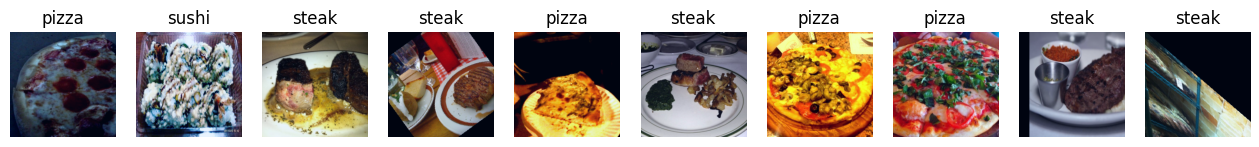

In [18]:
view_dataloader_images(train_dataloader_20_aug, 10)

In [19]:
effnet_0 = create_eff_model(0)
effnet_2 = create_eff_model(2)

models = {"effnet_0": effnet_0,
          "effnet_2": effnet_2}

train_dataloaders = {"data_20_percent": train_dataloader_20_percent,
                     "data_20_percent_aug": train_dataloader_20_aug}

num_epochs = [5, 10]

for dataloader_name, train_dataloader in train_dataloaders.items():
    for epochs in num_epochs:
        for model_name, model in models.items():
            loss_fn = nn.CrossEntropyLoss()
            optimizer = torch.optim.Adam(model.parameters(), lr=0.001)
            print(f"Training {model_name} with dataset {dataloader_name}")
            train(model, train_dataloader, test_dataloader, optimizer, loss_fn, epochs, device, 
                  create_writer(f"exercise_2-{dataloader_name}", model_name, f"epochs{epochs}"))

Training effnet_0 with dataset data_20_percent
[INFO] Created SummaryWriter, saving to: runs\2026-07-10\exercise_2-data_20_percent\effnet_0\epochs5...


  0%|          | 0/5 [00:00<?, ?it/s]

Epoch: 1 | train_loss: 0.9642 | train_acc: 0.5771 | test_loss: 0.6867 | test_acc: 0.9176
Epoch: 2 | train_loss: 0.7128 | train_acc: 0.7458 | test_loss: 0.5605 | test_acc: 0.8873
Epoch: 3 | train_loss: 0.5761 | train_acc: 0.8063 | test_loss: 0.4636 | test_acc: 0.9176
Epoch: 4 | train_loss: 0.4936 | train_acc: 0.8792 | test_loss: 0.4896 | test_acc: 0.8665
Epoch: 5 | train_loss: 0.4508 | train_acc: 0.8667 | test_loss: 0.3471 | test_acc: 0.9072
Training effnet_2 with dataset data_20_percent
[INFO] Created SummaryWriter, saving to: runs\2026-07-10\exercise_2-data_20_percent\effnet_2\epochs5...


  0%|          | 0/5 [00:00<?, ?it/s]

Epoch: 1 | train_loss: 0.9756 | train_acc: 0.5354 | test_loss: 0.7654 | test_acc: 0.8561
Epoch: 2 | train_loss: 0.7022 | train_acc: 0.8146 | test_loss: 0.6350 | test_acc: 0.8873
Epoch: 3 | train_loss: 0.5784 | train_acc: 0.8708 | test_loss: 0.5712 | test_acc: 0.8977
Epoch: 4 | train_loss: 0.4589 | train_acc: 0.8958 | test_loss: 0.5126 | test_acc: 0.8977
Epoch: 5 | train_loss: 0.4596 | train_acc: 0.8750 | test_loss: 0.4713 | test_acc: 0.9280
Training effnet_0 with dataset data_20_percent
[INFO] Created SummaryWriter, saving to: runs\2026-07-10\exercise_2-data_20_percent\effnet_0\epochs10...


...

Epoch: 1 | train_loss: 0.3894 | train_acc: 0.8771 | test_loss: 0.3186 | test_acc: 0.9280
Epoch: 2 | train_loss: 0.4226 | train_acc: 0.8396 | test_loss: 0.3472 | test_acc: 0.9186
Epoch: 3 | train_loss: 0.3035 | train_acc: 0.9042 | test_loss: 0.3028 | test_acc: 0.9280
Epoch: 4 | train_loss: 0.2997 | train_acc: 0.8771 | test_loss: 0.3207 | test_acc: 0.9280
Epoch: 5 | train_loss: 0.3200 | train_acc: 0.8938 | test_loss: 0.3434 | test_acc: 0.9176
Training effnet_0 with dataset data_20_percent_aug
[INFO] Created SummaryWriter, saving to: runs\2026-07-10\exercise_2-data_20_percent_aug\effnet_0\epochs10...


  0%|          | 0/10 [00:00<?, ?it/s]

Epoch: 1 | train_loss: 0.2520 | train_acc: 0.9167 | test_loss: 0.2183 | test_acc: 0.9593
Epoch: 2 | train_loss: 0.2570 | train_acc: 0.9313 | test_loss: 0.2132 | test_acc: 0.9489
Epoch: 3 | train_loss: 0.3022 | train_acc: 0.8854 | test_loss: 0.2171 | test_acc: 0.9489
Epoch: 4 | train_loss: 0.2407 | train_acc: 0.9354 | test_loss: 0.2167 | test_acc: 0.9489
Epoch: 5 | train_loss: 0.2601 | train_acc: 0.8812 | test_loss: 0.2092 | test_acc: 0.9384
Epoch: 6 | train_loss: 0.2514 | train_acc: 0.9167 | test_loss: 0.2314 | test_acc: 0.9489
Epoch: 7 | train_loss: 0.2505 | train_acc: 0.9042 | test_loss: 0.2080 | test_acc: 0.9489
Epoch: 8 | train_loss: 0.3380 | train_acc: 0.8354 | test_loss: 0.2137 | test_acc: 0.9280
Epoch: 9 | train_loss: 0.2760 | train_acc: 0.9083 | test_loss: 0.2304 | test_acc: 0.9384
Epoch: 10 | train_loss: 0.3028 | train_acc: 0.8958 | test_loss: 0.2150 | test_acc: 0.9489
Training effnet_2 with dataset data_20_percent_aug
[INFO] Created SummaryWriter, saving to: runs\2026-07-10\e

  0%|          | 0/10 [00:00<?, ?it/s]

Epoch: 1 | train_loss: 0.2655 | train_acc: 0.9125 | test_loss: 0.3220 | test_acc: 0.9384
Epoch: 2 | train_loss: 0.2390 | train_acc: 0.9333 | test_loss: 0.3303 | test_acc: 0.9384
Epoch: 3 | train_loss: 0.2737 | train_acc: 0.8958 | test_loss: 0.2976 | test_acc: 0.9280
Epoch: 4 | train_loss: 0.2574 | train_acc: 0.9208 | test_loss: 0.3464 | test_acc: 0.8977
Epoch: 5 | train_loss: 0.2386 | train_acc: 0.9187 | test_loss: 0.3307 | test_acc: 0.8778
Epoch: 6 | train_loss: 0.3007 | train_acc: 0.8958 | test_loss: 0.3482 | test_acc: 0.8674
Epoch: 7 | train_loss: 0.3093 | train_acc: 0.8667 | test_loss: 0.3010 | test_acc: 0.8883
Epoch: 8 | train_loss: 0.2514 | train_acc: 0.8854 | test_loss: 0.3102 | test_acc: 0.9081
Epoch: 9 | train_loss: 0.2503 | train_acc: 0.9167 | test_loss: 0.3884 | test_acc: 0.8674
Epoch: 10 | train_loss: 0.2115 | train_acc: 0.9479 | test_loss: 0.2890 | test_acc: 0.9384


data_20_percent_aug\effnet_0\epochs5 Acc最高

data_20_percent_aug\effnet_0\epochs10 Loss最小

## Exercise 3. Scale up the dataset to turn FoodVision Mini into FoodVision Big using the entire [Food101 dataset from `torchvision.models`](https://pytorch.org/vision/stable/generated/torchvision.datasets.Food101.html#torchvision.datasets.Food101)
    
* You could take the best performing model from your various experiments or even the EffNetB2 feature extractor we created in this notebook and see how it goes fitting for 5 epochs on all of Food101.
* If you try more than one model, it would be good to have the model's results tracked.
* If you load the Food101 dataset from `torchvision.models`, you'll have to create PyTorch DataLoaders to use it in training.
* **Note:** Due to the larger amount of data in Food101 compared to our pizza, steak, sushi dataset, this model will take longer to train.

In [17]:
DATA_DIR = Path("data")

food_train_dataset = torchvision.datasets.Food101(DATA_DIR, 'train', train_transform, None, True)
food_test_dataset = torchvision.datasets.Food101(DATA_DIR, 'test', simple_transform, None, True)
food_train_dataset, food_test_dataset

(Dataset Food101
     Number of datapoints: 75750
     Root location: data
     split=train
     StandardTransform
 Transform: Compose(
                  Resize(size=[224, 224], interpolation=InterpolationMode.BILINEAR, antialias=True)
                  TrivialAugmentWide(interpolation=InterpolationMode.NEAREST, num_magnitude_bins=31)
                  ToImage()
                  ToDtype(scale=True)
                  Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225], inplace=False)
            ),
 Dataset Food101
     Number of datapoints: 25250
     Root location: data
     split=test
     StandardTransform
 Transform: Compose(
                  Resize(size=[224, 224], interpolation=InterpolationMode.BILINEAR, antialias=True)
                  ToImage()
                  ToDtype(scale=True)
                  Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225], inplace=False)
            ))

In [22]:
from torch.utils.data import DataLoader

BATCH_SIZE = 256

food_train_dataloader = DataLoader(food_train_dataset, BATCH_SIZE,
                                   True, num_workers=2, pin_memory=True)
food_test_dataloader = DataLoader(food_test_dataset, BATCH_SIZE,
                                  False, num_workers=2, pin_memory=True)

food_train_dataloader, food_test_dataloader

(<torch.utils.data.dataloader.DataLoader at 0x24ef2a5a810>,
 <torch.utils.data.dataloader.DataLoader at 0x24ef29f3a10>)

In [23]:
weights = torchvision.models.EfficientNet_B2_Weights.DEFAULT
model = torchvision.models.efficientnet_b2(weights=weights).to(device)

for param in model.features.parameters():
    param.requires_grad = False

model.classifier

Sequential(
  (0): Dropout(p=0.3, inplace=True)
  (1): Linear(in_features=1408, out_features=1000, bias=True)
)

In [24]:
model.classifier = nn.Sequential(
    nn.Dropout(p=0.3, inplace=True),
    nn.Linear(in_features=1408, out_features=101) # 101 output classes for Food101 
).to(device)

In [ ]:
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

# train model for 1 epoch
results = train(model, food_train_dataloader, food_test_dataloader, optimizer, loss_fn, 1, device, create_writer("exercise_3-full-dataset-aug", "effnet_0", "epochs-5"))

[INFO] Created SummaryWriter, saving to: runs\2026-07-10\exercise_3-full-dataset-aug\effnet_0\epochs-5...


  0%|          | 0/1 [00:00<?, ?it/s]